# Data Audit — PubMed

PubMed is a citation network where nodes are scientific publications and edges are citations.
Each node has a TF-IDF weighted word-vector feature of dimension 500, and belongs to one of 3 diabetes-related classes.

In [1]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import to_networkx, degree
from collections import deque
from yfiles_jupyter_graphs import GraphWidget


## Load Dataset

In [2]:
dataset = Planetoid(root='data/', name='PubMed')
data = dataset[0]

print(f'Dataset:            {dataset}')
print(f'Number of graphs:   {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes:  {dataset.num_classes}')


Dataset:            PubMed()
Number of graphs:   1
Number of features: 500
Number of classes:  3


## Basic Graph Statistics

In [3]:
print(f'Number of nodes:    {data.num_nodes:,}')
print(f'Number of edges:    {data.num_edges:,}  (directed; undirected = {data.num_edges // 2:,})')
print(f'Average degree:     {data.num_edges / data.num_nodes:.2f}')
print(f'Has self-loops:     {data.has_self_loops()}')
print(f'Is undirected:      {data.is_undirected()}')


Number of nodes:    19,717
Number of edges:    88,648  (directed; undirected = 44,324)
Average degree:     4.50
Has self-loops:     False
Is undirected:      True


## Graph Visualization

PubMed is too large to render fully in a notebook widget, so we visualize a connected sampled subgraph using the same `GraphWidget` style as Cora.

To avoid artificial isolated nodes, we sample with a BFS expansion from a high-degree seed instead of truncating an arbitrary node list.

In [4]:
# Build an undirected NetworkX graph once from the PyG data object.
G_full = to_networkx(data, to_undirected=True)

def bfs_connected_sample(graph, seed, max_nodes=350):
    """Return up to max_nodes discovered by BFS; induced subgraph stays connected."""
    queue = deque([seed])
    seen = {seed}
    ordered_nodes = []

    while queue and len(ordered_nodes) < max_nodes:
        node = queue.popleft()
        ordered_nodes.append(node)

        # Visit high-degree neighbors first to keep the sample informative and dense.
        neighbors = sorted(graph.neighbors(node), key=graph.degree, reverse=True)
        for nbr in neighbors:
            if nbr not in seen:
                seen.add(nbr)
                queue.append(nbr)

    return ordered_nodes

seed_node = max(G_full.degree, key=lambda x: x[1])[0]
sample_nodes = bfs_connected_sample(G_full, seed_node, max_nodes=350)
G_vis = G_full.subgraph(sample_nodes).copy()

isolated_in_vis = sum(1 for _, d in G_vis.degree() if d == 0)
print(f"Sampled nodes: {G_vis.number_of_nodes()} | edges: {G_vis.number_of_edges()} | isolated in sample: {isolated_in_vis}")

graph_widget = GraphWidget(graph=G_vis)
graph_widget.set_edge_label_mapping(lambda x, y: '')
graph_widget.show()


Sampled nodes: 350 | edges: 923 | isolated in sample: 0


GraphWidget(layout=Layout(height='800px', width='100%'))

## Class (Label) Distribution

The 3 classes correspond to diabetes research sub-topics: Diabetes Mellitus Experimental, Type 1, and Type 2.

Diabetes Mellitus\nExperimental    4103
Diabetes Mellitus\nType 1          7739
Diabetes Mellitus\nType 2          7875

Class balance (min/max ratio): 0.52


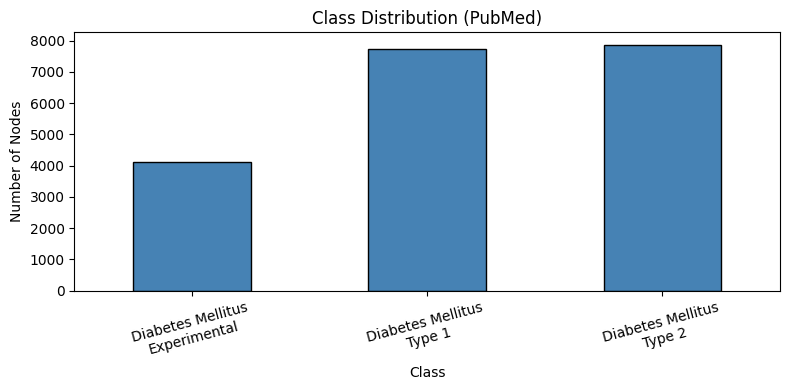

In [5]:
class_names = ['Diabetes Mellitus\nExperimental', 'Diabetes Mellitus\nType 1', 'Diabetes Mellitus\nType 2']
label_counts = pd.Series(data.y.numpy()).value_counts().sort_index()
label_counts.index = class_names

print(label_counts.to_string())
print(f'\nClass balance (min/max ratio): {label_counts.min() / label_counts.max():.2f}')

fig, ax = plt.subplots(figsize=(8, 4))
label_counts.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Class Distribution (PubMed)')
ax.set_xlabel('Class')
ax.set_ylabel('Number of Nodes')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()


## Data Quality — Missing Values

In [6]:
import torch

nan_in_features = torch.isnan(data.x).sum().item()
nan_in_labels   = torch.isnan(data.y.float()).sum().item()

print(f'NaN values in node features: {int(nan_in_features)}')
print(f'NaN values in labels:        {int(nan_in_labels)}')


NaN values in node features: 0
NaN values in labels:        0


## Feature Statistics & Sparsity

Node features are TF-IDF weighted word vectors (dim=500). Unlike Cora's binary BoW, these are continuous non-negative values.

In [7]:
x = data.x.numpy()
total_entries   = x.size
nonzero_entries = (x != 0).sum()
sparsity = 1 - nonzero_entries / total_entries

print(f'Feature matrix shape:           {x.shape}')
print(f'Non-zero entries:               {nonzero_entries:,}')
print(f'Sparsity:                       {sparsity:.2%}')
print(f'Avg non-zero features per node: {nonzero_entries / x.shape[0]:.1f}')
print(f'Feature value range:            [{x.min():.4f}, {x.max():.4f}]')
print(f'Feature mean:                   {x.mean():.6f}')
print(f'Feature std:                    {x.std():.6f}')


Feature matrix shape:           (19717, 500)
Non-zero entries:               988,031
Sparsity:                       89.98%
Avg non-zero features per node: 50.1
Feature value range:            [0.0000, 1.2633]
Feature mean:                   0.003927
Feature std:                    0.017594


## Degree Distribution

Average degree: 4.50
Max degree:     171
Min degree:     1


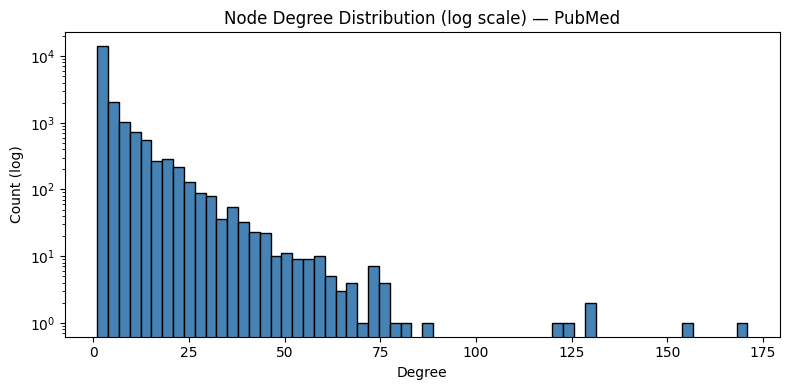

In [8]:
deg = degree(data.edge_index[0], num_nodes=data.num_nodes).numpy()

print(f'Average degree: {deg.mean():.2f}')
print(f'Max degree:     {int(deg.max())}')
print(f'Min degree:     {int(deg.min())}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(deg, bins=60, color='steelblue', edgecolor='black', log=True)
ax.set_title('Node Degree Distribution (log scale) — PubMed')
ax.set_xlabel('Degree')
ax.set_ylabel('Count (log)')
plt.tight_layout()
plt.show()


## Graph Connectivity

PubMed has ~20k nodes so we skip full visualisation and just check connectivity stats.

In [9]:
Gnx = to_networkx(data, to_undirected=True)

components = list(nx.connected_components(Gnx))
sizes = sorted([len(c) for c in components], reverse=True)

print(f'Is connected:              {nx.is_connected(Gnx)}')
print(f'Number of components:      {len(components)}')
print(f'Largest component size:    {sizes[0]:,} nodes  ({sizes[0]/Gnx.number_of_nodes():.1%} of all nodes)')
if len(sizes) > 1:
    print(f'2nd largest component:     {sizes[1]} nodes')
print(f'Isolated nodes (degree=0): {sum(1 for _, d in Gnx.degree() if d == 0)}')


Is connected:              True
Number of components:      1
Largest component size:    19,717 nodes  (100.0% of all nodes)
Isolated nodes (degree=0): 0


## Standard Train / Val / Test Split

PubMed uses the same semi-supervised split convention as Cora (Yang et al., 2016):
- **Train**: 60 nodes (20 per class × 3 classes)
- **Validation**: 500 nodes
- **Test**: 1,000 nodes

The remainder are unlabelled during training.

In [10]:
n_train = int(data.train_mask.sum())
n_val   = int(data.val_mask.sum())
n_test  = int(data.test_mask.sum())
n_total = data.num_nodes
n_unlabelled = n_total - n_train - n_val - n_test

print(f'Total nodes:       {n_total:,}')
print(f'Train nodes:       {n_train}  ({n_train/n_total:.1%})')
print(f'Val nodes:         {n_val}   ({n_val/n_total:.1%})')
print(f'Test nodes:        {n_test}  ({n_test/n_total:.1%})')
print(f'Unlabelled (rest): {n_unlabelled:,}  ({n_unlabelled/n_total:.1%})')


Total nodes:       19,717
Train nodes:       60  (0.3%)
Val nodes:         500   (2.5%)
Test nodes:        1000  (5.1%)
Unlabelled (rest): 18,157  (92.1%)


## Embeddings Preview

In [11]:
cols = [f'tfidf_{i}' for i in range(data.x.shape[1])]
preview_df = pd.DataFrame(data.x.numpy(), columns=cols)

print(f'PubMed embedding matrix shape: {tuple(data.x.shape)}')
preview_df.head()


PubMed embedding matrix shape: (19717, 500)


,tfidf_0,tfidf_1,tfidf_2,tfidf_3,tfidf_4,tfidf_5,tfidf_6,tfidf_7,tfidf_8,tfidf_9,...,tfidf_490,tfidf_491,tfidf_492,tfidf_493,tfidf_494,tfidf_495,tfidf_496,tfidf_497,tfidf_498,tfidf_499
0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.004999,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.016434,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.104636,0.0,0.0,0.0,0.035178,0.0,0.0,0.019555,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.008582,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.007356,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
